# Evaluate a single EpiHydra clock

Loads the EpiHydra model (LoRA-adapted MethylGPT backbone + AgePredictor head), selects one clock head, and reports MAE / R² / Pearson r with a predicted-vs-target scatter plot.

- `CLOCK = "age"` (default) uses the head already stored in `best_model.pt`, so no head swapping is needed.
- Any other clock (e.g. `"phenoage_age"`) swaps in `best_head_<CLOCK>.pt` from `HEAD_PATH`.

Helper functions live in `eval_utils.py`.

## Parameters
Set everything here, then run all cells.

In [2]:
from pathlib import Path

# ── Which clock to evaluate ──────────────────────────────────────
CLOCK      = "phenoage_age"     # "age" (default) or a clock head name, e.g. "phenoage_age"
EVAL_SPLIT = "train"    # "train", "valid" or "test"

# ── Paths ────────────────────────────────────────────────────────
ROOT          = Path("/work/gr-fe/bryan/EpiHydra")
DATA_PATH     = ROOT / "data/03_final/GSE41037/methylation.pkl"
MODEL_PATH    = ROOT / "data/03_final/methylgpt/medium"   # MethylGPT backbone + vocab + args.json
EPIHYDRA_PATH = ROOT / "results/tensorboard/checkpoints/nlayers6_nhead4_emb256_lr1e-04_bs32_mask0.3_heads4_20260902_105750"
HEAD_PATH     = ROOT / "results/tensorboard/ckpt/clocks4_nlayers6_nhead4_emb256_lora_lr1e-04_bs32_mask0.15_heads4_20261105_072540"

# ── Data split (must match training so the test set is truly held out) ──
SPLIT_RATIOS = dict(train_ratio=None, valid_ratio=None, test_ratio=None)
BATCH_SIZE   = 16
RANDOM_STATE = 42

## Imports

In [3]:
import json
import pickle
import warnings

# Silence noisy but harmless library warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
warnings.filterwarnings("ignore", message=".*flash_attn.*")
warnings.filterwarnings("ignore", message=".*nested tensor.*")

import matplotlib.pyplot as plt
import torch

%matplotlib inline

from methylgpt import MethylGPTModel, MethylVocab
from scgpt.tokenizer import tokenize_and_pad_batch, random_mask_value
import eval_utils as eu
from epihydra import VocabWrapper
from train import build_dataloaders, evaluate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
print(f"Evaluating clock: '{CLOCK}' on the {EVAL_SPLIT} split")

ModuleNotFoundError: No module named 'eval_utils'

## Load data, config and vocab

In [17]:
print("Loading data...")
with open(DATA_PATH, "rb") as f:
    data = pickle.load(f)

# MethylGPT pre-training config (layer sizes, number of CpGs, ...)
with open(MODEL_PATH / "args.json") as f:
    pretrain_config = json.load(f)

# CpG vocabulary used for tokenisation
vocab = VocabWrapper(MODEL_PATH / "vocab.json", pretrain_config["n_hvg"])

Loading data...


## Build dataloaders
Clock heads reuse the scaler they were trained with. For `"age"` (or any clock without a saved scaler) `build_dataloaders` fits a new one on the training split.

In [18]:
scaler = eu.load_scaler(CLOCK, HEAD_PATH)

splits = build_dataloaders(
    data         = data,
    vocab        = vocab,
    clock_age    = CLOCK,          # target column in the metadata
    batch_size   = BATCH_SIZE,
    num_workers  = 0,
    random_state = RANDOM_STATE,
    verbose      = True,
    scaler       = scaler,
    **SPLIT_RATIOS,
)
scaler = splits["scaler"]          # the scaler actually used (supplied or newly fitted)
loaders = {
    "train": splits["train_loader"],
    "valid": splits["valid_loader"],
    "test" : splits["test_loader"],
}

Samples in meta : 720
Samples in CpG  : 720
Common samples  : 720
Samples after NaN drop : 720

Vocab CpGs : 49,159 | Present : 49,156 (100.0%) | Missing : 3
ℹ  Missing CpGs → NaN → padded during tokenisation.

Train : 705 | Valid : 7 | Test : 8
Age range (train) : -5.6 – 68.2 years
ℹ  Reusing supplied pre-fitted scaler.
✓ Data loaded and ready.



## Build the model and load weights
The backbone is wrapped with LoRA *before* loading the checkpoint so the parameter names match.

In [19]:
age_model = eu.build_age_model(MODEL_PATH, vocab, pretrain_config, device, num_heads=4)

state = eu.load_clock_state(EPIHYDRA_PATH, HEAD_PATH, clock=CLOCK, device=device)
print(age_model.load_state_dict(state))
age_model.eval();

/work/gr-fe/bryan/miniconda3/envs/methylgpt/lib/python3.11/site-packages/torch/nn/modules/transformer.py:286: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer was not TransformerEncoderLayer
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


Loaded all params from /work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/medium/medium-best_model_epoch6.pt
trainable params: 258,064 || all params: 15,680,786 || trainable%: 1.6457
<All keys matched successfully>


## Evaluate

In [20]:
mae, preds, labels = evaluate(age_model, loaders[EVAL_SPLIT], scaler, device)
metrics = eu.eval_metrics(labels, preds, mae, split=EVAL_SPLIT)


────────────────────────────────────────
  Train MAE      : 13.66 years
  Train R²       : -0.271
  Train Pearson r: 0.665
────────────────────────────────────────



## Predicted vs. target age

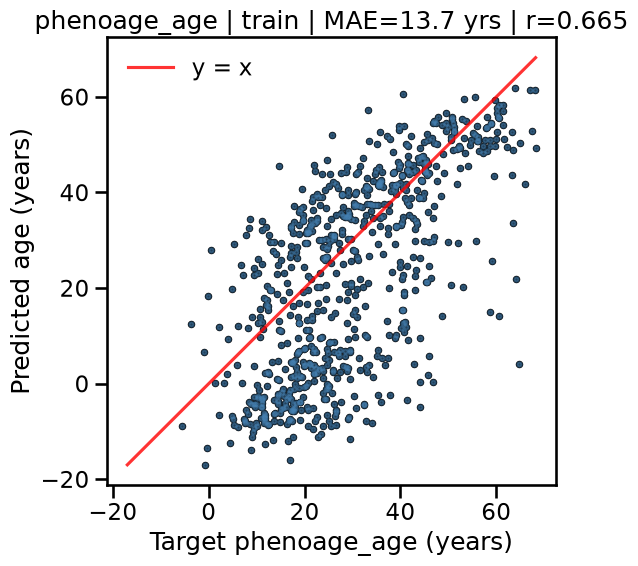

In [21]:
eu.plot_predictions(labels, preds, metrics, clock=CLOCK, split=EVAL_SPLIT)
plt.show()